# Predicting Building Damage Severity from Earthquakes Using Structural and Geographic Features
### A KDD-Based Predictive Analytics Approach — CA3, Predictive Analytics (Sem VII, Batch 2023-27)

**Student:** Maheen Rajesh Meshram  |  **PRN:** 23070521085  |  **Section:** B

This notebook follows the Knowledge Discovery in Databases (KDD) process end to end:

| # | KDD stage | Notebook section |
|---|---|---|
| 1 | Problem identification | §1 |
| 2 | Data selection | §2 |
| 3 | Data understanding | §3 |
| 4 | Preprocessing (cleaning) | §4 |
| 5 | Exploratory analysis & hypothesis testing | §5 |
| 6 | Feature engineering | §6 |
| 7 | Stratified train–test split | §7 |
| 8 | Transformation (encoding, scaling) | §8 |
| 9 | Data mining — model building | §9 |
| 10 | Class-imbalance handling | §10 |
| 11 | Hyperparameter tuning (cross-validation) | §11 |
| 12 | Evaluation | §12 |
| 13 | Interpretation (feature importance, SHAP) | §13 |
| 14 | Knowledge discovery & policy insights | §14 |

## 1. Problem Identification

On 25 April 2015 the M<sub>w</sub> 7.8 Gorkha earthquake struck Nepal, damaging or destroying hundreds of thousands of buildings. After an earthquake, authorities must decide quickly where to send rescue and inspection teams, and before the next one they must decide which buildings to retrofit first. Inspecting every building by hand is slow and expensive.

**Objective.** Build a multi-class classification model that predicts the damage grade of a building

* **1** – low damage, **2** – medium damage, **3** – near-complete destruction

using only information that is known *before* an earthquake: structure (age, floors, area, height, foundation, roof, floor types, superstructure materials), land surface condition, ownership/use, and geographic region. Then interpret the model to find which construction practices and regions are most vulnerable.

**Primary metric:** micro-averaged F1 (the official metric of the DrivenData competition; equal to accuracy for single-label multi-class). **Secondary:** macro-F1 and per-class recall, because the minority class (grade 1) is easy to ignore.

In [1]:
import warnings, time, os
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, kruskal

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, recall_score)
import lightgbm as lgb
import xgboost as xgb
import shap, joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
os.makedirs('figures', exist_ok=True)
os.makedirs('models', exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')
print('Libraries loaded')

Libraries loaded


## 2. Data Selection

**Source:** *Richter's Predictor: Modeling Earthquake Damage* (DrivenData), derived from the 2015 Nepal Earthquake Open Data Portal. The survey was carried out by Kathmandu Living Labs and the Central Bureau of Statistics (National Planning Commission Secretariat, Nepal) and is one of the largest post-disaster datasets ever collected.

Two files are used: `train_values.csv` (38 features per building) and `train_labels.csv` (damage grade). They are joined on `building_id`. The competition `test_values.csv` has no labels, so it is not used; instead a held-out test set is carved from the labelled data (§7).

In [2]:
values = pd.read_csv('data/train_values.csv')
labels = pd.read_csv('data/train_labels.csv')
df = values.merge(labels, on='building_id', how='inner', validate='one_to_one')
print('values:', values.shape, '| labels:', labels.shape, '| merged:', df.shape)
df.head()

values: (260601, 39) | labels: (260601, 2) | merged: (260601, 40)


,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,3


## 3. Data Understanding
### 3.1 Feature dictionary

In [3]:
geo = ['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']
num = ['count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'count_families']
cat = ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type',
       'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']
sup = [c for c in df.columns if c.startswith('has_superstructure_')]
sec = [c for c in df.columns if c.startswith('has_secondary_use')]
TARGET = 'damage_grade'

dictionary = pd.DataFrame({
    'group': ['Geographic (region IDs, coarse → fine)', 'Numeric structural', 'Categorical construction (obfuscated letters)',
              'Binary superstructure material flags', 'Binary secondary-use flags', 'Target'],
    'n_features': [len(geo), len(num), len(cat), len(sup), len(sec), 1],
    'columns': [', '.join(geo), ', '.join(num), ', '.join(cat), ', '.join(s.replace('has_superstructure_','') for s in sup),
                ', '.join(s.replace('has_secondary_use_','') for s in sec), TARGET]})
pd.set_option('display.max_colwidth', 200)
dictionary

,group,n_features,columns
0,"Geographic (region IDs, coarse → fine)",3,"geo_level_1_id, geo_level_2_id, geo_level_3_id"
1,Numeric structural,5,"count_floors_pre_eq, age, area_percentage, height_percentage, count_families"
2,Categorical construction (obfuscated letters),8,"land_surface_condition, foundation_type, roof_type, ground_floor_type, other_floor_type, position, plan_configuration, legal_ownership_status"
3,Binary superstructure material flags,11,"adobe_mud, mud_mortar_stone, stone_flag, cement_mortar_stone, mud_mortar_brick, cement_mortar_brick, timber, bamboo, rc_non_engineered, rc_engineered, other"
4,Binary secondary-use flags,11,"has_secondary_use, agriculture, hotel, rental, institution, school, industry, health_post, gov_office, use_police, other"
5,Target,1,damage_grade


In [4]:
print('Missing values (total):', df.isna().sum().sum())
print('Unique building_id :', df.building_id.nunique(), 'of', len(df))
print()
print(df[geo].nunique().rename('distinct values'))
print()
print(df[cat].nunique().rename('distinct levels'))
df[num].describe().T.round(2)

Missing values (total): 0
Unique building_id : 260601 of 260601

geo_level_1_id       31
geo_level_2_id     1414
geo_level_3_id    11595
Name: distinct values, dtype: int64

land_surface_condition     3
foundation_type            5
roof_type                  3
ground_floor_type          5
other_floor_type           4
position                   4
plan_configuration        10
legal_ownership_status     4
Name: distinct levels, dtype: int64


,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,260601.0,2.13,0.73,1.0,2.0,2.0,2.0,9.0
age,260601.0,26.54,73.57,0.0,10.0,15.0,30.0,995.0
area_percentage,260601.0,8.02,4.39,1.0,5.0,7.0,9.0,100.0
height_percentage,260601.0,5.43,1.92,2.0,4.0,5.0,6.0,32.0
count_families,260601.0,0.98,0.42,0.0,1.0,1.0,1.0,9.0


### 3.2 Class distribution of the target

,buildings,percent
damage_grade,,
1,25124,9.64
2,148259,56.89
3,87218,33.47


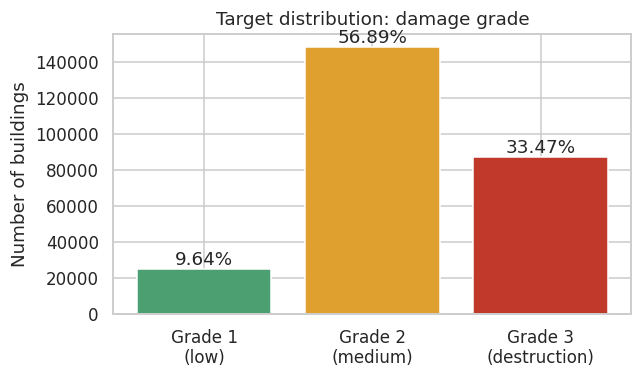

Imbalance ratio (majority/minority): 5.9


In [5]:
dist = df[TARGET].value_counts().sort_index()
pct = (dist / len(df) * 100).round(2)
display(pd.DataFrame({'buildings': dist, 'percent': pct}))

fig, ax = plt.subplots(figsize=(6, 3.6))
bars = ax.bar(['Grade 1\n(low)', 'Grade 2\n(medium)', 'Grade 3\n(destruction)'], dist.values,
              color=['#4C9F70', '#E0A030', '#C0392B'])
for b, p in zip(bars, pct.values):
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f'{p}%', ha='center', va='bottom')
ax.set_ylabel('Number of buildings'); ax.set_title('Target distribution: damage grade')
savefig('fig01_class_distribution'); plt.show()
print('Imbalance ratio (majority/minority):', round(dist.max()/dist.min(), 2))

**Observation.** The target is imbalanced: grade 2 is the majority (≈57 %), grade 1 the minority (≈9.6 %). A model that always predicts grade 2 already scores ≈0.57 micro-F1, so this is the baseline every model must beat, and macro-F1 / grade-1 recall must be watched.

## 4. Preprocessing (Data Cleaning)
### 4.1 Duplicates

In [6]:
full_dup = df.duplicated().sum()
feat_cols = [c for c in df.columns if c not in ['building_id', TARGET]]
feat_dup = df.duplicated(subset=feat_cols).sum()
conflict = (df.groupby(feat_cols, observed=True)[TARGET].nunique() > 1).sum()
print('Exact duplicate rows (incl. id)          :', full_dup)
print('Rows identical in all 38 features        :', feat_dup)
print('Feature-identical groups with different label:', conflict)

Exact duplicate rows (incl. id)          : 0
Rows identical in all 38 features        : 16191
Feature-identical groups with different label: 3825


There are no duplicate records (every `building_id` is unique). About 6 % of rows share identical features with another building — these are genuinely similar houses in the same village, not data-entry repeats, so they are **kept**. Some of these identical-feature groups carry *different* damage grades, which shows there is irreducible noise: the same type of house in the same place can suffer different damage. This puts a ceiling on achievable accuracy.

### 4.2 Outliers in age, area and height

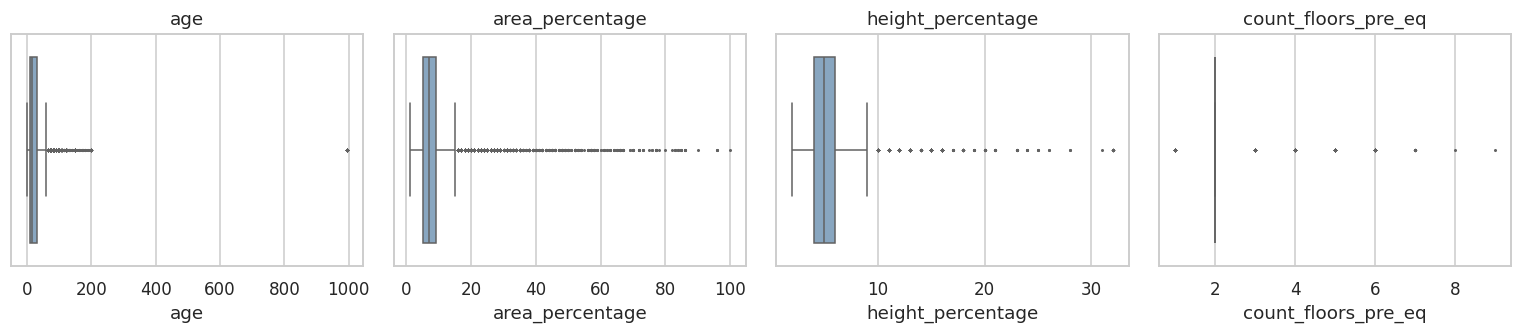

Age value counts at the top end:
age
180       7
185       1
190       3
195       2
200     106
995    1390
Name: count, dtype: int64


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, c in zip(axes, ['age', 'area_percentage', 'height_percentage', 'count_floors_pre_eq']):
    sns.boxplot(x=df[c], ax=ax, color='#7FA7C9', fliersize=1)
    ax.set_title(c)
savefig('fig02_outliers_boxplots'); plt.show()

print('Age value counts at the top end:')
print(df['age'].value_counts().sort_index().tail(6))

In [8]:
n995 = (df['age'] == 995).sum()
print(f'age == 995 : {n995} buildings ({n995/len(df)*100:.2f}%) — a sentinel code, not a real age')

# Flag the sentinel and cap it at the next largest genuine value
df['age_unknown_995'] = (df['age'] == 995).astype(int)
real_max = df.loc[df['age'] != 995, 'age'].max()
df.loc[df['age'] == 995, 'age'] = real_max

# Cap area / height at the 99.5th percentile (winsorising) to limit the leverage of extreme values
caps = {}
for c in ['area_percentage', 'height_percentage']:
    caps[c] = df[c].quantile(0.995)
    n = (df[c] > caps[c]).sum()
    df[c] = df[c].clip(upper=caps[c])
    print(f'{c}: capped {n} values above {caps[c]:.0f}')
print('age capped to', real_max)

age == 995 : 1390 buildings (0.53%) — a sentinel code, not a real age
area_percentage: capped 1270 values above 28
height_percentage: capped 768 values above 13
age capped to 200


Note: winsorising thresholds are computed on the full labelled data only for these two simple percentile caps; they use no target information, so they do not leak the label. All target-dependent transformations (target encoding) are fitted on the training split only (§8).

### 4.3 Consistency checks on binary flag columns

In [9]:
binary_cols = sup + sec + ['age_unknown_995']
bad_binary = [c for c in binary_cols if not set(df[c].unique()) <= {0, 1}]
print('Binary columns with values other than 0/1:', bad_binary or 'none')

# has_secondary_use must be 1 whenever any specific secondary use is 1
specific = [c for c in sec if c != 'has_secondary_use']
inconsistent = ((df[specific].sum(axis=1) > 0) & (df['has_secondary_use'] == 0)).sum()
reverse = ((df[specific].sum(axis=1) == 0) & (df['has_secondary_use'] == 1)).sum()
print('Specific use = 1 but has_secondary_use = 0 :', inconsistent)
print('has_secondary_use = 1 but no specific use  :', reverse)

# every building should have at least one superstructure material
no_material = (df[sup].sum(axis=1) == 0).sum()
print('Buildings with no superstructure material flagged:', no_material)

# floors vs height: a taller building should not have a lower height percentage, check correlation
print('corr(floors, height_percentage) =', round(df[['count_floors_pre_eq','height_percentage']].corr().iloc[0,1], 3))

Binary columns with values other than 0/1: none
Specific use = 1 but has_secondary_use = 0 : 0
has_secondary_use = 1 but no specific use  : 0
Buildings with no superstructure material flagged: 0
corr(floors, height_percentage) = 0.79


The flag columns are clean and logically consistent: all values are 0/1, the parent flag `has_secondary_use` agrees with its children, every building has at least one superstructure material, and floor count and height percentage move together as expected. No rows needed to be removed.

## 5. Exploratory Data Analysis & Hypothesis Testing
### 5.1 Damage by superstructure material

,material,buildings,grade_1_%,grade_3_%,mean_grade
2,stone_flag,8947,2.03,47.29,2.45
1,mud_mortar_stone,198561,4.41,38.20,2.34
0,adobe_mud,23101,2.57,37.25,2.35
4,mud_mortar_brick,17761,3.51,30.63,2.27
6,timber,66450,11.50,28.02,2.17
10,other,3905,16.80,25.63,2.09
7,bamboo,22154,12.81,23.99,2.11
3,cement_mortar_stone,4752,17.45,14.20,1.97
8,rc_non_engineered,11099,34.75,12.70,1.78
5,cement_mortar_brick,19615,36.22,5.55,1.69


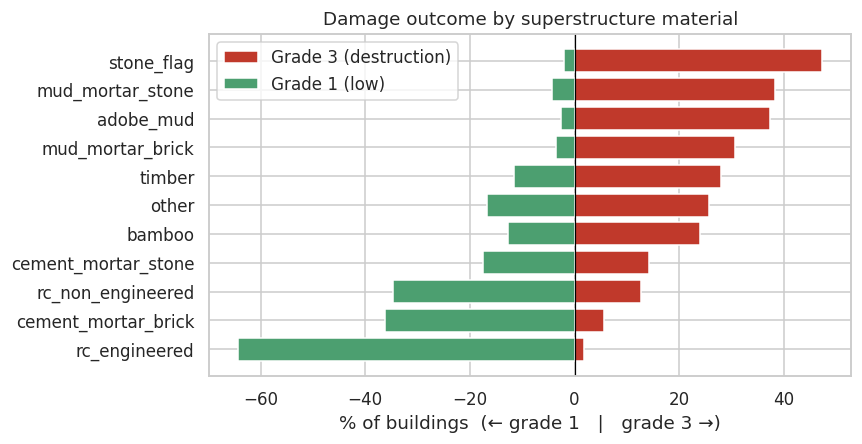

In [10]:
rows = []
for c in sup:
    sub = df[df[c] == 1]
    rows.append({'material': c.replace('has_superstructure_', ''), 'buildings': len(sub),
                 'grade_1_%': (sub[TARGET]==1).mean()*100, 'grade_3_%': (sub[TARGET]==3).mean()*100,
                 'mean_grade': sub[TARGET].mean()})
mat = pd.DataFrame(rows).sort_values('grade_3_%', ascending=False).round(2)
display(mat)

fig, ax = plt.subplots(figsize=(8, 4.2))
order = mat.sort_values('grade_3_%')
ax.barh(order['material'], order['grade_3_%'], color='#C0392B', label='Grade 3 (destruction)')
ax.barh(order['material'], -order['grade_1_%'], color='#4C9F70', label='Grade 1 (low)')
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('% of buildings  (← grade 1   |   grade 3 →)')
ax.set_title('Damage outcome by superstructure material')
ax.legend(loc='upper left')
savefig('fig03_damage_by_material'); plt.show()

Mud-mortar stone, adobe/mud and stone construction show the highest share of near-complete destruction, while reinforced-concrete (RC) engineered and cement-mortar brick buildings are mostly grade 1 or 2. Material is clearly a strong signal.

### 5.2 Damage by age and number of floors

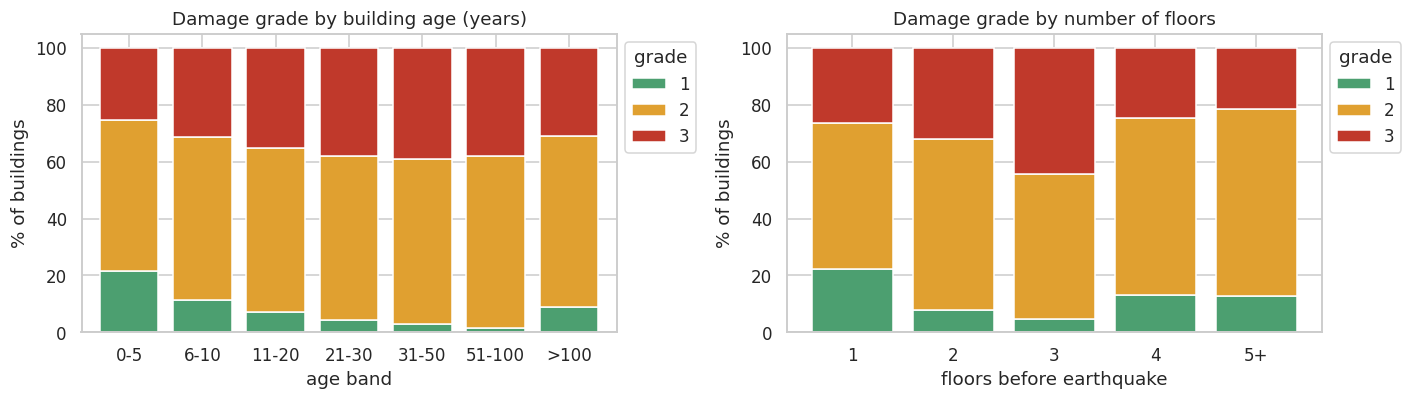

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
age_bins = pd.cut(df['age'], bins=[-1, 5, 10, 20, 30, 50, 100, 1000],
                  labels=['0-5', '6-10', '11-20', '21-30', '31-50', '51-100', '>100'])
ct = pd.crosstab(age_bins, df[TARGET], normalize='index') * 100
ct.plot(kind='bar', stacked=True, ax=axes[0], color=['#4C9F70', '#E0A030', '#C0392B'], width=0.8)
axes[0].set_title('Damage grade by building age (years)'); axes[0].set_ylabel('% of buildings'); axes[0].set_xlabel('age band')
axes[0].legend(title='grade', bbox_to_anchor=(1, 1)); axes[0].tick_params(axis='x', rotation=0)

fl = df['count_floors_pre_eq'].clip(upper=5)
ct2 = pd.crosstab(fl, df[TARGET], normalize='index') * 100
ct2.index = [str(i) if i < 5 else '5+' for i in ct2.index]
ct2.plot(kind='bar', stacked=True, ax=axes[1], color=['#4C9F70', '#E0A030', '#C0392B'], width=0.8)
axes[1].set_title('Damage grade by number of floors'); axes[1].set_xlabel('floors before earthquake'); axes[1].set_ylabel('% of buildings')
axes[1].legend(title='grade', bbox_to_anchor=(1, 1)); axes[1].tick_params(axis='x', rotation=0)
savefig('fig04_damage_by_age_floors'); plt.show()

### 5.3 Damage by foundation and roof type

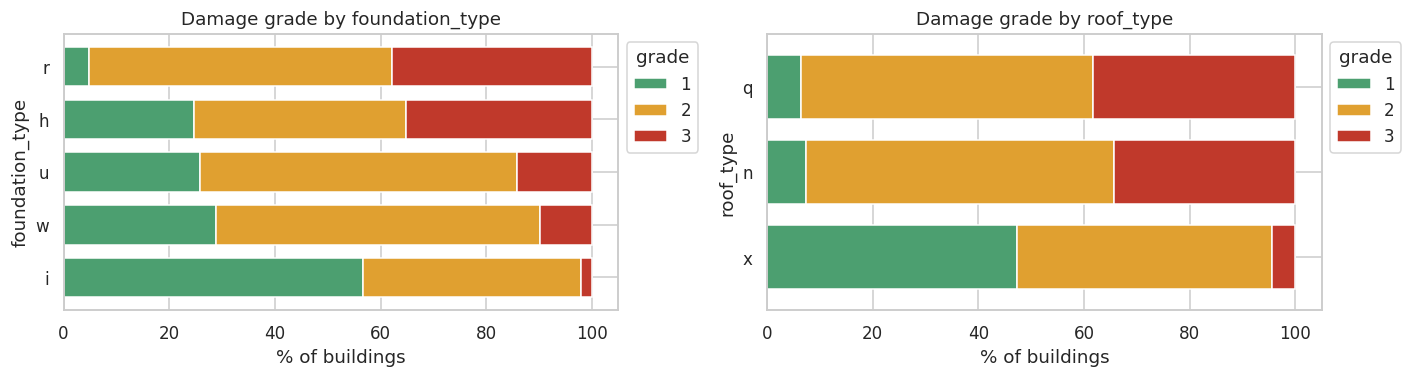

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, c in zip(axes, ['foundation_type', 'roof_type']):
    ct = pd.crosstab(df[c], df[TARGET], normalize='index') * 100
    ct = ct.sort_values(3)
    ct.plot(kind='barh', stacked=True, ax=ax, color=['#4C9F70', '#E0A030', '#C0392B'], width=0.75)
    ax.set_title(f'Damage grade by {c}'); ax.set_xlabel('% of buildings'); ax.legend(title='grade', bbox_to_anchor=(1, 1))
savefig('fig05_damage_by_foundation_roof'); plt.show()

### 5.4 Damage by region (geo_level_1)

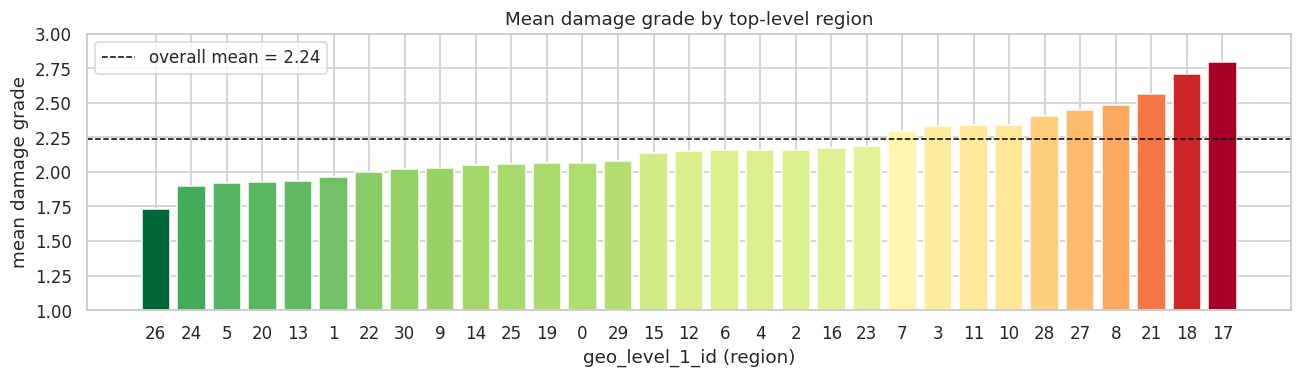

Spread of mean grade across regions: 1.73 to 2.79


In [13]:
reg = df.groupby('geo_level_1_id')[TARGET].agg(buildings='size', mean_grade='mean',
                                               pct_grade3=lambda s: (s == 3).mean() * 100).sort_values('mean_grade')
fig, ax = plt.subplots(figsize=(12, 3.6))
colors = plt.cm.RdYlGn_r((reg['mean_grade'] - reg['mean_grade'].min()) / (reg['mean_grade'].max() - reg['mean_grade'].min()))
ax.bar(reg.index.astype(str), reg['mean_grade'], color=colors)
ax.axhline(df[TARGET].mean(), color='black', ls='--', lw=1, label=f'overall mean = {df[TARGET].mean():.2f}')
ax.set_xlabel('geo_level_1_id (region)'); ax.set_ylabel('mean damage grade'); ax.set_ylim(1, 3)
ax.set_title('Mean damage grade by top-level region'); ax.legend()
savefig('fig06_damage_by_region'); plt.show()
print('Spread of mean grade across regions:', round(reg.mean_grade.min(), 2), 'to', round(reg.mean_grade.max(), 2))

Location matters a great deal: the mean grade ranges from close to 1 in some regions to well above 2.5 in others, reflecting distance from the epicentre, soil and local building practice. This is why the high-cardinality region IDs need careful encoding (§8).

### 5.5 Hypothesis testing

* **Categorical features** — chi-square test of independence. H<sub>0</sub>: the feature and damage grade are independent. Effect size: Cramér's V.
* **Numeric features** — Kruskal–Wallis test (non-parametric, since the distributions are skewed). H<sub>0</sub>: the feature's distribution is the same in all three grades.

In [14]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, dof, _ = chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    return chi2, p, np.sqrt(chi2 / (n * (min(r, k) - 1)))

tests = []
for c in cat + sup + ['has_secondary_use', 'geo_level_1_id']:
    chi2, p, v = cramers_v(df[c], df[TARGET])
    tests.append({'feature': c, 'test': 'chi-square', 'statistic': chi2, 'p_value': p, 'effect (Cramér V)': v})
for c in num:
    groups = [df.loc[df[TARGET] == g, c] for g in [1, 2, 3]]
    h, p = kruskal(*groups)
    tests.append({'feature': c, 'test': 'Kruskal-Wallis', 'statistic': h, 'p_value': p, 'effect (Cramér V)': np.nan})
tests = pd.DataFrame(tests)
tests['reject H0 (α=0.05)'] = tests['p_value'] < 0.05
tests.sort_values('effect (Cramér V)', ascending=False).round(4).head(20)

,feature,test,statistic,p_value,effect (Cramér V),reject H0 (α=0.05)
20,geo_level_1_id,chi-square,72583.3989,0.0,0.3732,True
9,has_superstructure_mud_mortar_stone,chi-square,29276.0350,0.0,0.3352,True
1,foundation_type,chi-square,48547.1607,0.0,0.3052,True
13,has_superstructure_cement_mortar_brick,chi-square,20491.7976,0.0,0.2804,True
3,ground_floor_type,chi-square,36430.8490,0.0,0.2644,True
4,other_floor_type,chi-square,31487.3919,0.0,0.2458,True
2,roof_type,chi-square,30251.4193,0.0,0.2409,True
17,has_superstructure_rc_engineered,chi-square,14643.5361,0.0,0.2370,True
16,has_superstructure_rc_non_engineered,chi-square,9113.6698,0.0,0.1870,True
19,has_secondary_use,chi-square,1672.8179,0.0,0.0801,True


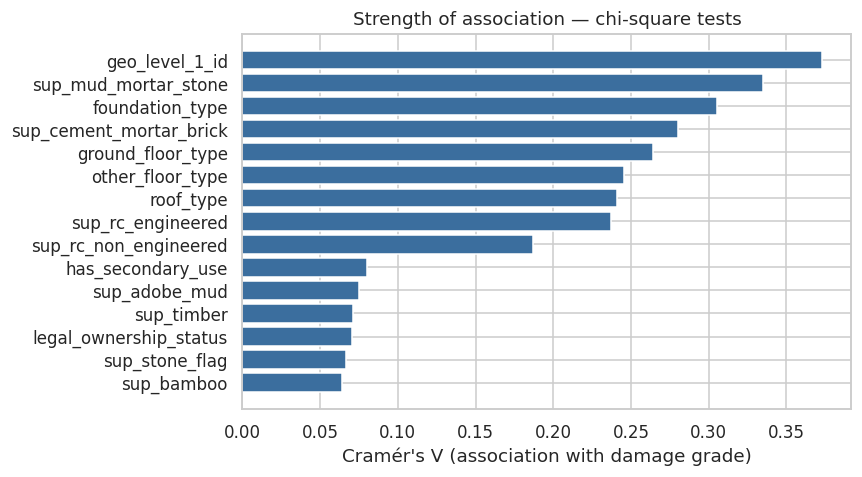

Features where H0 is NOT rejected: []


In [15]:
top = tests.dropna(subset=['effect (Cramér V)']).sort_values('effect (Cramér V)').tail(15)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top['feature'].str.replace('has_superstructure_', 'sup_'), top['effect (Cramér V)'], color='#3B6E9E')
ax.set_xlabel("Cramér's V (association with damage grade)")
ax.set_title('Strength of association — chi-square tests')
savefig('fig07_cramers_v'); plt.show()
print('Features where H0 is NOT rejected:', tests.loc[~tests['reject H0 (α=0.05)'], 'feature'].tolist())

With 260 k buildings nearly every p-value is tiny, so statistical significance alone is not informative; the **effect size** is. The region (geo_level_1), mud-mortar stone superstructure, foundation, roof and floor types show the strongest associations. This guides feature engineering and confirms that location and material should dominate the model.

## 6. Feature Engineering

New features built from domain reasoning (all use only pre-earthquake information, no target):

| Feature | Definition | Rationale |
|---|---|---|
| `volume_proxy` | area_percentage × height_percentage | Overall building size / mass |
| `area_per_floor` | area_percentage / floors | Footprint per storey |
| `height_per_floor` | height_percentage / floors | Storey height (slender storeys are weaker) |
| `age_band` | ordinal bins of age | Captures non-linear ageing effect |
| `n_materials` | count of superstructure flags | Mixed construction |
| `weak_material` | adobe/mud, mud-mortar stone, stone, mud-mortar brick, bamboo or timber | Low-strength, non-engineered materials |
| `has_rc` | RC engineered or non-engineered | Reinforced-concrete frame present |
| `families_per_floor` | families / floors | Occupancy density |

In [16]:
def engineer(d):
    d = d.copy()
    d['volume_proxy'] = d['area_percentage'] * d['height_percentage']
    d['area_per_floor'] = d['area_percentage'] / d['count_floors_pre_eq']
    d['height_per_floor'] = d['height_percentage'] / d['count_floors_pre_eq']
    d['age_band'] = pd.cut(d['age'], bins=[-1, 5, 10, 20, 30, 50, 100, 1000], labels=False).astype(int)
    d['n_materials'] = d[sup].sum(axis=1)
    weak = ['has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag',
            'has_superstructure_mud_mortar_brick', 'has_superstructure_bamboo', 'has_superstructure_timber']
    d['weak_material'] = (d[weak].sum(axis=1) > 0).astype(int)
    d['has_rc'] = ((d['has_superstructure_rc_engineered'] + d['has_superstructure_rc_non_engineered']) > 0).astype(int)
    d['families_per_floor'] = d['count_families'] / d['count_floors_pre_eq']
    return d

df = engineer(df)
eng = ['volume_proxy', 'area_per_floor', 'height_per_floor', 'age_band', 'n_materials',
       'weak_material', 'has_rc', 'families_per_floor']
display(df.groupby('weak_material')[TARGET].value_counts(normalize=True).unstack().round(3).rename(index={0:'no weak material',1:'weak material'}))
display(df.groupby('has_rc')[TARGET].value_counts(normalize=True).unstack().round(3).rename(index={0:'no RC',1:'RC present'}))

damage_grade,1,2,3
weak_material,,,
no weak material,0.472,0.486,0.042
weak material,0.061,0.577,0.362


damage_grade,1,2,3
has_rc,,,
no RC,0.076,0.575,0.349
RC present,0.426,0.476,0.098


The engineered flags behave as expected: buildings with a weak material are far more likely to be destroyed, and buildings with an RC frame are far more likely to escape with grade 1.

## 7. Stratified Train–Test Split

The split is done **before** any target-dependent transformation or resampling, so the test set stays completely unseen (no data leakage). Stratification keeps the 9.6 / 56.9 / 33.5 % class ratio identical in both parts.

In [17]:
FEATURES = geo + num + cat + sup + sec + ['age_unknown_995'] + eng
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print('train:', X_train.shape, ' test:', X_test.shape)
pd.DataFrame({'train %': y_train.value_counts(normalize=True).sort_index()*100,
              'test %': y_test.value_counts(normalize=True).sort_index()*100}).round(2)

train: (208480, 47)  test: (52121, 47)


,train %,test %
damage_grade,,
1,9.64,9.64
2,56.89,56.89
3,33.47,33.47


## 8. Transformation — Encoding and Scaling

* **Low-cardinality categoricals** (8 columns, 3–10 levels) → one-hot encoding.
* **High-cardinality region IDs** (31 / 1 414 / 11 595 levels) → one-hot would create >13 000 sparse columns, and plain label codes are meaningless numbers. Instead we use **target encoding**: each region is replaced by the smoothed proportion of each damage grade in that region. scikit-learn's `TargetEncoder` uses **internal 5-fold cross-fitting** on the training data, so a building's own label never leaks into its own encoding, and it is fitted on the training set only. For three classes it produces 3 columns per geo level (9 columns in total).
* **Numeric features** → standard scaling (needed for Logistic Regression; harmless for trees).
* Binary flags are passed through unchanged.

In [18]:
passthrough = sup + sec + ['age_unknown_995', 'weak_material', 'has_rc', 'n_materials', 'age_band']
numeric = num + ['volume_proxy', 'area_per_floor', 'height_per_floor', 'families_per_floor']

def make_preprocessor(scale=True):
    return ColumnTransformer([
        ('geo_te', TargetEncoder(target_type='multiclass', smooth='auto', cv=5, random_state=RANDOM_STATE), geo),
        ('cat_ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat),
        ('num', StandardScaler() if scale else 'passthrough', numeric),
        ('bin', 'passthrough', passthrough)], verbose_feature_names_out=False)

pre = make_preprocessor()
Xtr_t = pre.fit_transform(X_train, y_train)
Xte_t = pre.transform(X_test)
feature_names = list(pre.get_feature_names_out())
print('Transformed train matrix:', Xtr_t.shape)
print('First geo-encoded columns:', feature_names[:9])

Transformed train matrix: (208480, 83)
First geo-encoded columns: ['geo_level_1_id_1', 'geo_level_1_id_2', 'geo_level_1_id_3', 'geo_level_2_id_1', 'geo_level_2_id_2', 'geo_level_2_id_3', 'geo_level_3_id_1', 'geo_level_3_id_2', 'geo_level_3_id_3']


## 9. Data Mining — Model Building

Five models of increasing capacity are compared against a majority-class baseline:

1. **Dummy (most frequent)** – the floor any useful model must beat
2. **Logistic Regression** (multinomial) – linear, interpretable baseline
3. **Decision Tree** – non-linear, human-readable rules
4. **Random Forest** – bagged ensemble of trees
5. **XGBoost** – gradient-boosted trees
6. **LightGBM** – gradient-boosted trees with histogram splitting (fast on 200 k rows)

All models are trained on the same transformed training matrix and scored on the same untouched test set. Micro-F1 is the primary metric.

In [19]:
def evaluate(name, model, Xtr, ytr, Xte, yte, fit=True):
    t0 = time.time()
    if fit: model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    pred = np.asarray(pred).ravel()
    rec = recall_score(yte, pred, average=None, labels=[1, 2, 3])
    return {'model': name, 'micro_F1': f1_score(yte, pred, average='micro'),
            'macro_F1': f1_score(yte, pred, average='macro'),
            'weighted_F1': f1_score(yte, pred, average='weighted'),
            'recall_g1': rec[0], 'recall_g2': rec[1], 'recall_g3': rec[2],
            'train_time_s': time.time() - t0}, pred

# XGBoost expects labels 0..K-1
class XGBWrap(xgb.XGBClassifier):
    def fit(self, X, y, **kw): return super().fit(X, np.asarray(y) - 1, **kw)
    def predict(self, X): return super().predict(X) + 1

models = {
    'Dummy (majority)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000, C=1.0),
    'Decision Tree': DecisionTreeClassifier(max_depth=14, min_samples_leaf=20, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=3, max_features='sqrt',
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost': XGBWrap(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8,
                       tree_method='hist', n_jobs=-1, random_state=RANDOM_STATE, verbosity=0),
    'LightGBM': lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63,
                                   subsample=0.9, subsample_freq=1, colsample_bytree=0.8,
                                   random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
}
results, preds = [], {}
for name, m in models.items():
    r, p = evaluate(name, m, Xtr_t, y_train, Xte_t, y_test)
    results.append(r); preds[name] = p
    print(f"{name:22s} micro-F1={r['micro_F1']:.4f}  macro-F1={r['macro_F1']:.4f}  ({r['train_time_s']:.0f}s)")
res = pd.DataFrame(results).set_index('model').round(4)
res

Dummy (majority)       micro-F1=0.5689  macro-F1=0.2417  (0s)


Logistic Regression    micro-F1=0.7392  macro-F1=0.6763  (28s)


Decision Tree          micro-F1=0.7297  macro-F1=0.6722  (3s)


Random Forest          micro-F1=0.7527  macro-F1=0.6998  (59s)


XGBoost                micro-F1=0.7513  macro-F1=0.7027  (53s)


LightGBM               micro-F1=0.7513  macro-F1=0.7024  (42s)


,micro_F1,macro_F1,weighted_F1,recall_g1,recall_g2,recall_g3,train_time_s
model,,,,,,,
Dummy (majority),0.5689,0.2417,0.4126,0.0000,1.0000,0.0000,0.0511
Logistic Regression,0.7392,0.6763,0.7330,0.4697,0.8493,0.6298,28.0961
Decision Tree,0.7297,0.6722,0.7247,0.5095,0.8342,0.6156,3.0073
Random Forest,0.7527,0.6998,0.7474,0.5194,0.8575,0.6418,59.2751
XGBoost,0.7513,0.7027,0.7468,0.5489,0.8503,0.6415,53.0188
LightGBM,0.7513,0.7024,0.7467,0.5449,0.8497,0.6434,41.6754


## 10. Class-Imbalance Handling

Two common remedies are compared on the strongest model family (LightGBM), always applied to the **training data only**:

* **Class weights** (`class_weight='balanced'`) – errors on rare grade-1 buildings cost more during training.
* **SMOTE** – synthetic grade-1 / grade-3 samples are generated by interpolation between neighbours. Applied only after the split, on the transformed training matrix.

The trade-off is between micro-F1 (overall accuracy, which favours the majority class) and macro-F1 / grade-1 recall (fairness to the minority class).

In [20]:
from imblearn.over_sampling import SMOTE
base_params = dict(n_estimators=500, learning_rate=0.05, num_leaves=63, subsample=0.9, subsample_freq=1,
                   colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)

imb = [dict(res.loc['LightGBM']) | {'model': 'LightGBM – no rebalancing'}]
r, p_cw = evaluate('LightGBM – class weights', lgb.LGBMClassifier(class_weight='balanced', **base_params),
                   Xtr_t, y_train, Xte_t, y_test)
imb.append(r)

t0 = time.time()
sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=5)
Xs, ys = sm.fit_resample(Xtr_t, y_train)
print('SMOTE resampled train size:', Xs.shape, '| class counts:', dict(pd.Series(ys).value_counts().sort_index()),
      f'({time.time()-t0:.0f}s)')
r, p_sm = evaluate('LightGBM – SMOTE', lgb.LGBMClassifier(**base_params), Xs, ys, Xte_t, y_test)
imb.append(r)
del Xs, ys
imb = pd.DataFrame(imb).set_index('model')[['micro_F1', 'macro_F1', 'recall_g1', 'recall_g2', 'recall_g3']].round(4)
imb

SMOTE resampled train size: (355821, 83) | class counts: {1: np.int64(118607), 2: np.int64(118607), 3: np.int64(118607)} (36s)


,micro_F1,macro_F1,recall_g1,recall_g2,recall_g3
model,,,,,
LightGBM – no rebalancing,0.7513,0.7024,0.5449,0.8497,0.6434
LightGBM – class weights,0.7110,0.6860,0.8513,0.6686,0.7425
LightGBM – SMOTE,0.7048,0.6791,0.7787,0.6620,0.7561


**Interpretation.** Both remedies raise grade-1 recall substantially, but at a cost in overall micro-F1 because more grade-2 buildings are pushed into grade 1. Which option is "best" depends on the use case:

* For the competition objective and for estimating total reconstruction need, **no rebalancing** maximises micro-F1.
* For a triage tool where missing a safe building is cheap but missing a destroyed one is costly, class weights give a more balanced error profile.

The tuned final model in §11 therefore keeps the unweighted objective (primary metric = micro-F1), and the class-weighted variant is reported alongside it.

## 11. Hyperparameter Tuning with Cross-Validation

Tuning is done in **two stages** (coarse-to-fine), entirely on the training set:

1. **Stage 1 — broad random search.** `RandomizedSearchCV` (10 configurations × 3-fold stratified CV) on a stratified 60 000-row sample of the training data. This is cheap enough to explore the space on a single CPU.
2. **Stage 2 — confirmation on the full training set.** Hyperparameters that win on a small sample often under-fit when the data is 3.5× larger (e.g. fewer leaves, stronger regularisation look best on 60 k rows). So the top-3 stage-1 configurations plus the default configuration from §9 are re-scored with 3-fold CV on all 208 k training rows, and the winner becomes the final model.

The whole preprocessing pipeline sits *inside* the CV, so the target encoder is re-fitted on each training fold and never sees its validation fold. The test set is not touched at any point of tuning.

In [21]:
pipe = Pipeline([('pre', make_preprocessor(scale=False)),
                 ('clf', lgb.LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, subsample_freq=1))])
param_dist = {
    'clf__n_estimators': [300, 500, 800],
    'clf__learning_rate': [0.03, 0.05, 0.08],
    'clf__num_leaves': [31, 63, 127],
    'clf__min_child_samples': [10, 20, 40],
    'clf__subsample': [0.8, 0.9, 1.0],
    'clf__colsample_bytree': [0.6, 0.8, 1.0],
    'clf__reg_lambda': [0, 1, 5],
}
X_s, _, y_s, _ = train_test_split(X_train, y_train, train_size=60000, stratify=y_train, random_state=RANDOM_STATE)
search = RandomizedSearchCV(pipe, param_dist, n_iter=10, scoring='f1_micro',
                            cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                            random_state=RANDOM_STATE, n_jobs=1, verbose=0)
t0 = time.time(); search.fit(X_s, y_s)
print(f'Search finished in {time.time()-t0:.0f}s')
print('Best stage-1 CV micro-F1 (60k sample):', round(search.best_score_, 4))
{k.replace('clf__', ''): v for k, v in search.best_params_.items()}

Search finished in 525s
Best stage-1 CV micro-F1 (60k sample): 0.7264


{'subsample': 0.8,
 'reg_lambda': 5,
 'num_leaves': 31,
 'n_estimators': 300,
 'min_child_samples': 20,
 'learning_rate': 0.05,
 'colsample_bytree': 0.6}

In [22]:
cv_table = pd.DataFrame(search.cv_results_)[['mean_test_score', 'std_test_score'] +
                                            [c for c in search.cv_results_ if c.startswith('param_clf__')]]
cv_table.columns = [c.replace('param_clf__', '') for c in cv_table.columns]
cv_table.sort_values('mean_test_score', ascending=False).round(4).head(10)

,mean_test_score,std_test_score,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree
8,0.7264,0.0036,0.8,5,31,300,20,0.05,0.6
6,0.7259,0.0037,0.9,5,31,800,40,0.05,0.6
9,0.7254,0.0030,0.8,5,127,300,10,0.03,1.0
4,0.7253,0.0034,0.8,0,127,300,40,0.03,1.0
0,0.7250,0.0040,1.0,1,127,500,20,0.03,0.8
3,0.7237,0.0037,0.8,5,63,500,20,0.05,0.8
7,0.7221,0.0038,1.0,1,127,300,10,0.08,0.8
2,0.7202,0.0044,1.0,1,127,800,20,0.05,0.8
5,0.7162,0.0013,0.8,0,63,800,40,0.08,1.0
1,0.7162,0.0039,0.9,5,127,800,10,0.08,0.8


In [23]:
from sklearn.model_selection import cross_val_score
default_cfg = dict(n_estimators=500, learning_rate=0.05, num_leaves=63, min_child_samples=20,
                   subsample=0.9, colsample_bytree=0.8, reg_lambda=0)
ranked = search.cv_results_['rank_test_score'].argsort()
candidates = {f'stage-1 rank {r+1}': {k.replace('clf__', ''): v for k, v in search.cv_results_['params'][i].items()}
              for r, i in enumerate(ranked[:3])}
candidates['default (§9)'] = default_cfg

def lgb_pipe(params):
    return Pipeline([('pre', make_preprocessor(scale=False)),
                     ('clf', lgb.LGBMClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1, subsample_freq=1))])

stage2 = []
cv_full = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
for name, params in candidates.items():
    t0 = time.time()
    sc = cross_val_score(lgb_pipe(params), X_train, y_train, cv=cv_full, scoring='f1_micro', n_jobs=1)
    stage2.append({'candidate': name, 'cv_micro_F1_mean': sc.mean(), 'cv_std': sc.std(), 'secs': time.time() - t0, **params})
    print(f"{name:18s} full-train 3-fold micro-F1 = {sc.mean():.4f} ± {sc.std():.4f}  ({time.time()-t0:.0f}s)")
stage2 = pd.DataFrame(stage2).sort_values('cv_micro_F1_mean', ascending=False).reset_index(drop=True)
best_name = stage2.loc[0, 'candidate']
best_params = candidates[best_name]
print('\nSelected configuration:', best_name, best_params)
stage2.round(4)

stage-1 rank 1     full-train 3-fold micro-F1 = 0.7427 ± 0.0013  (71s)


stage-1 rank 2     full-train 3-fold micro-F1 = 0.7438 ± 0.0013  (177s)


stage-1 rank 3     full-train 3-fold micro-F1 = 0.7433 ± 0.0014  (110s)


default (§9)       full-train 3-fold micro-F1 = 0.7437 ± 0.0008  (108s)

Selected configuration: stage-1 rank 2 {'subsample': 0.9, 'reg_lambda': 5, 'num_leaves': 31, 'n_estimators': 800, 'min_child_samples': 40, 'learning_rate': 0.05, 'colsample_bytree': 0.6}


,candidate,cv_micro_F1_mean,cv_std,secs,subsample,reg_lambda,num_leaves,n_estimators,min_child_samples,learning_rate,colsample_bytree
0,stage-1 rank 2,0.7438,0.0013,177.2851,0.9,5,31,800,40,0.05,0.6
1,default (§9),0.7437,0.0008,108.1013,0.9,0,63,500,20,0.05,0.8
2,stage-1 rank 3,0.7433,0.0014,110.1755,0.8,5,127,300,10,0.03,1.0
3,stage-1 rank 1,0.7427,0.0013,71.1397,0.8,5,31,300,20,0.05,0.6


In [24]:
final_model = lgb_pipe(best_params)
t0 = time.time()
final_model.fit(X_train, y_train)
r, p_final = evaluate('LightGBM – tuned (final)', final_model, None, None, X_test, y_test, fit=False)
r['train_time_s'] = time.time() - t0
res = pd.concat([res, pd.DataFrame([r]).set_index('model').round(4)])
preds['LightGBM – tuned (final)'] = p_final
joblib.dump(final_model, 'models/final_lightgbm_pipeline.joblib')
stage2.to_csv('results_tuning_stage2.csv', index=False)
print('Saved models/final_lightgbm_pipeline.joblib')
res

Saved models/final_lightgbm_pipeline.joblib


,micro_F1,macro_F1,weighted_F1,recall_g1,recall_g2,recall_g3,train_time_s
model,,,,,,,
Dummy (majority),0.5689,0.2417,0.4126,0.0000,1.0000,0.0000,0.0511
Logistic Regression,0.7392,0.6763,0.7330,0.4697,0.8493,0.6298,28.0961
Decision Tree,0.7297,0.6722,0.7247,0.5095,0.8342,0.6156,3.0073
Random Forest,0.7527,0.6998,0.7474,0.5194,0.8575,0.6418,59.2751
XGBoost,0.7513,0.7027,0.7468,0.5489,0.8503,0.6415,53.0188
LightGBM,0.7513,0.7024,0.7467,0.5449,0.8497,0.6434,41.6754
LightGBM – tuned (final),0.7514,0.7021,0.7468,0.5445,0.8503,0.6430,76.5994


## 12. Evaluation
### 12.1 Model comparison

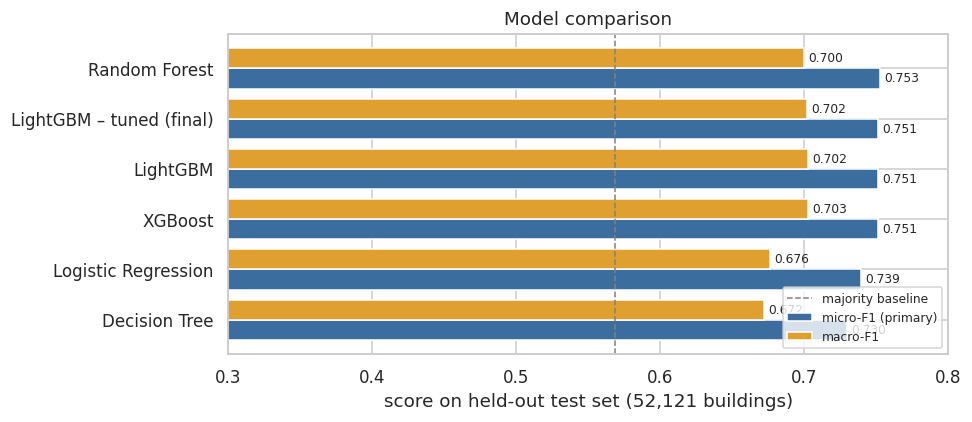

In [25]:
comp = res.drop(index='Dummy (majority)').sort_values('micro_F1')
fig, ax = plt.subplots(figsize=(9, 4))
yv = np.arange(len(comp))
ax.barh(yv - 0.2, comp['micro_F1'], height=0.4, label='micro-F1 (primary)', color='#3B6E9E')
ax.barh(yv + 0.2, comp['macro_F1'], height=0.4, label='macro-F1', color='#E0A030')
ax.axvline(res.loc['Dummy (majority)', 'micro_F1'], color='grey', ls='--', lw=1, label='majority baseline')
for i, (a, b) in enumerate(zip(comp['micro_F1'], comp['macro_F1'])):
    ax.text(a + 0.003, i - 0.2, f'{a:.3f}', va='center', fontsize=8)
    ax.text(b + 0.003, i + 0.2, f'{b:.3f}', va='center', fontsize=8)
ax.set_yticks(yv); ax.set_yticklabels(comp.index); ax.set_xlim(0.3, 0.8)
ax.set_xlabel('score on held-out test set (52,121 buildings)'); ax.set_title('Model comparison')
ax.legend(loc='lower right', fontsize=8)
savefig('fig08_model_comparison'); plt.show()

### 12.2 Final model — classification report and confusion matrix

Final tuned LightGBM — held-out test set
                       precision    recall  f1-score   support

        Grade 1 (low)     0.6895    0.5445    0.6085      5025
     Grade 2 (medium)     0.7514    0.8503    0.7978     29652
Grade 3 (destruction)     0.7684    0.6430    0.7001     17444

             accuracy                         0.7514     52121
            macro avg     0.7364    0.6793    0.7021     52121
         weighted avg     0.7511    0.7514    0.7468     52121



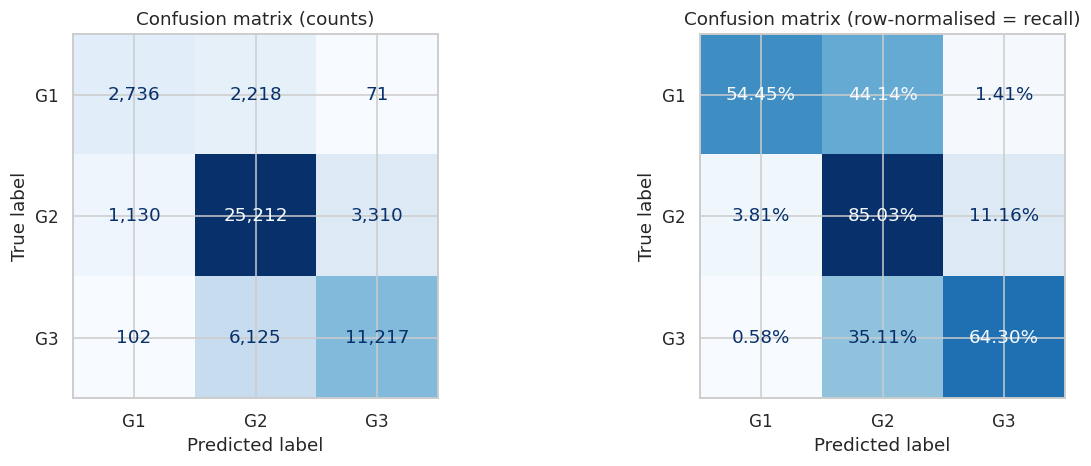

Two-grade errors (G1 predicted as G3 or vice versa): 173 of 52121 (0.33%)


In [26]:
print('Final tuned LightGBM — held-out test set')
print(classification_report(y_test, p_final, target_names=['Grade 1 (low)', 'Grade 2 (medium)', 'Grade 3 (destruction)'], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
cm = confusion_matrix(y_test, p_final, labels=[1, 2, 3])
ConfusionMatrixDisplay(cm, display_labels=['G1', 'G2', 'G3']).plot(ax=axes[0], cmap='Blues', colorbar=False, values_format=',')
axes[0].set_title('Confusion matrix (counts)')
cmn = confusion_matrix(y_test, p_final, labels=[1, 2, 3], normalize='true')
ConfusionMatrixDisplay(cmn, display_labels=['G1', 'G2', 'G3']).plot(ax=axes[1], cmap='Blues', colorbar=False, values_format='.2%')
axes[1].set_title('Confusion matrix (row-normalised = recall)')
savefig('fig09_confusion_matrix'); plt.show()

far = ((y_test.values == 1) & (p_final == 3)).sum() + ((y_test.values == 3) & (p_final == 1)).sum()
print(f'Two-grade errors (G1 predicted as G3 or vice versa): {far} of {len(y_test)} ({far/len(y_test)*100:.2f}%)')

### 12.3 Generalisation check
Train vs test score and the cross-validation spread show whether the model over-fits.

In [27]:
train_pred = final_model.predict(X_train)
gen = pd.DataFrame({'micro_F1': [f1_score(y_train, train_pred, average='micro'), f1_score(y_test, p_final, average='micro')],
                    'macro_F1': [f1_score(y_train, train_pred, average='macro'), f1_score(y_test, p_final, average='macro')]},
                   index=['train (208k)', 'test (52k)']).round(4)
display(gen)
print(f"Full-train 3-fold CV micro-F1 of chosen configuration: {stage2.loc[0,'cv_micro_F1_mean']:.4f} ± {stage2.loc[0,'cv_std']:.4f}")
print(f"Train–test gap: {(gen.iloc[0,0]-gen.iloc[1,0])*100:.2f} percentage points")

,micro_F1,macro_F1
train (208k),0.7726,0.7321
test (52k),0.7514,0.7021


Full-train 3-fold CV micro-F1 of chosen configuration: 0.7438 ± 0.0013
Train–test gap: 2.12 percentage points


## 13. Interpretation
### 13.1 Feature importance (LightGBM gain)

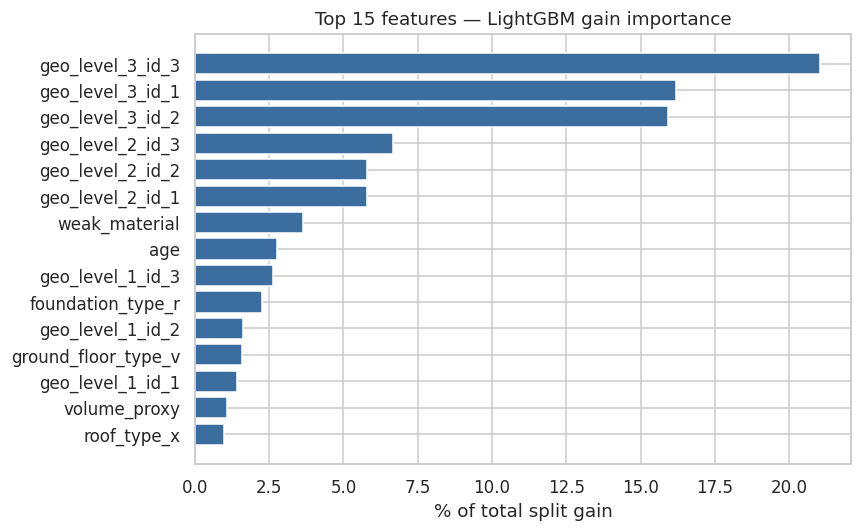

Share of gain from the 9 target-encoded geo columns: 77.1 %


In [28]:
clf = final_model.named_steps['clf']
fn = list(final_model.named_steps['pre'].get_feature_names_out())
imp = pd.Series(clf.booster_.feature_importance(importance_type='gain'), index=fn)
imp = (imp / imp.sum() * 100).sort_values(ascending=False)
top15 = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([s.replace('has_superstructure_', 'sup_') for s in top15.index], top15.values, color='#3B6E9E')
ax.set_xlabel('% of total split gain'); ax.set_title('Top 15 features — LightGBM gain importance')
savefig('fig10_feature_importance'); plt.show()
print('Share of gain from the 9 target-encoded geo columns:', round(imp[[c for c in fn if c.startswith('geo_level')]].sum(), 1), '%')

### 13.2 SHAP explanation
SHAP (SHapley Additive exPlanations) attributes each prediction to the features that drove it. Below: the mean |SHAP| for the **grade 3 (destruction)** output on a 3 000-building test sample, and the beeswarm showing direction of effect.

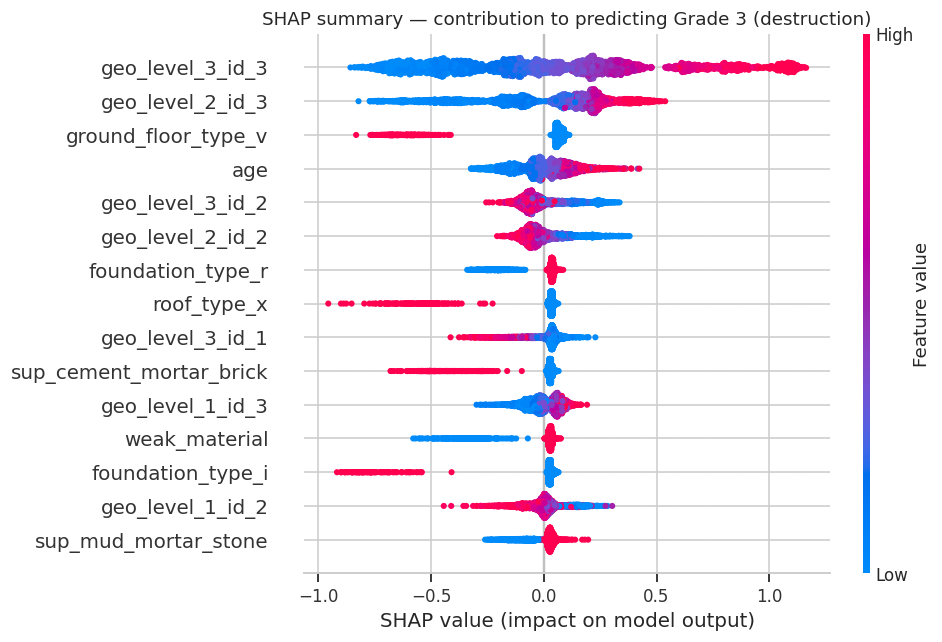

In [29]:
pre_f = final_model.named_steps['pre']
Xs_te = X_test.sample(3000, random_state=RANDOM_STATE)
Xs_t = pd.DataFrame(pre_f.transform(Xs_te), columns=fn)
explainer = shap.TreeExplainer(clf)
sv = explainer.shap_values(Xs_t)
sv3 = sv[:, :, 2] if np.ndim(sv) == 3 else sv[2]          # class index 2 = grade 3
Xs_disp = Xs_t.rename(columns=lambda s: s.replace('has_superstructure_', 'sup_'))
plt.figure()
shap.summary_plot(sv3, Xs_disp, max_display=15, show=False, plot_size=(9, 6))
plt.title('SHAP summary — contribution to predicting Grade 3 (destruction)')
savefig('fig11_shap_grade3'); plt.show()

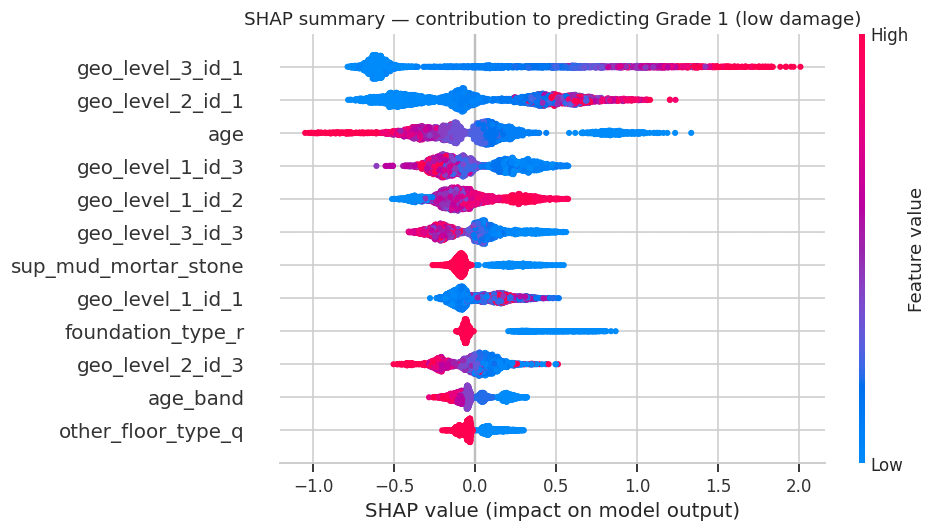

In [30]:
sv1 = sv[:, :, 0] if np.ndim(sv) == 3 else sv[0]
plt.figure()
shap.summary_plot(sv1, Xs_disp, max_display=12, show=False, plot_size=(9, 5))
plt.title('SHAP summary — contribution to predicting Grade 1 (low damage)')
savefig('fig12_shap_grade1'); plt.show()

**Reading the SHAP plots.** Red = high feature value, blue = low. Points to the right push the prediction *towards* that grade.

* The target-encoded region columns (e.g. `geo_level_*_3`, the share of grade-3 buildings in that locality) dominate: location is the single strongest driver.
* A **mud-mortar stone** superstructure pushes strongly towards grade 3 and away from grade 1.
* **RC / cement-mortar brick** construction, certain foundation and roof types, and lower age push towards grade 1.
* Larger area per floor (bigger footprints) is mildly protective; very tall, slender storeys are not.

## 14. Knowledge Discovery & Policy Insights
### 14.1 Predicted risk by building type
The final model's predicted probability of destruction (grade 3) is averaged over typical construction profiles on the test set.

,buildings,mean_pred_p_g3,actual_g3_rate
profile,,,
Mud-mortar stone only,29354,40.6,40.5
Adobe / mud,2889,38.8,38.8
Mud-mortar stone + timber,9349,32.3,31.9
Other,4367,21.4,21.9
RC non-engineered,2210,12.8,13.3
Cement-mortar brick,3141,5.9,5.8
RC engineered,811,2.0,1.6


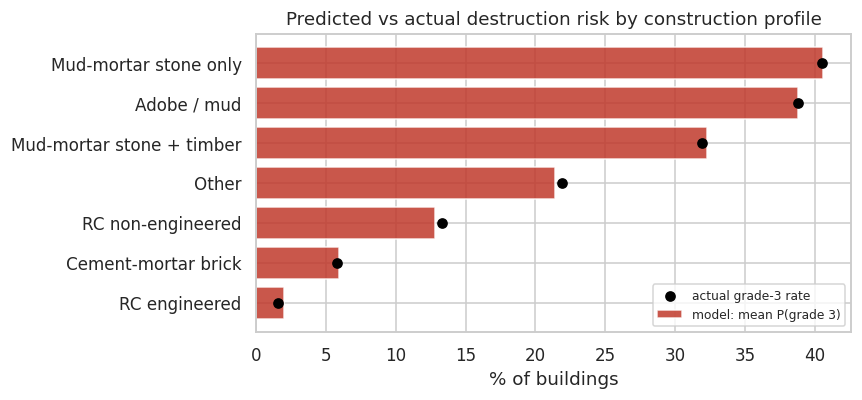

In [31]:
proba = final_model.predict_proba(X_test)
risk = X_test.copy()
risk['p_destruction'] = proba[:, 2]
risk['actual_g3'] = (y_test == 3).astype(int)

def profile(r):
    if r['has_superstructure_rc_engineered'] == 1: return 'RC engineered'
    if r['has_superstructure_rc_non_engineered'] == 1: return 'RC non-engineered'
    if r['has_superstructure_cement_mortar_brick'] == 1: return 'Cement-mortar brick'
    if r['has_superstructure_mud_mortar_stone'] == 1 and r['has_superstructure_timber'] == 1: return 'Mud-mortar stone + timber'
    if r['has_superstructure_mud_mortar_stone'] == 1: return 'Mud-mortar stone only'
    if r['has_superstructure_adobe_mud'] == 1: return 'Adobe / mud'
    return 'Other'
risk['profile'] = risk.apply(profile, axis=1)
prof = risk.groupby('profile').agg(buildings=('p_destruction', 'size'),
                                   mean_pred_p_g3=('p_destruction', 'mean'),
                                   actual_g3_rate=('actual_g3', 'mean')).sort_values('mean_pred_p_g3', ascending=False)
prof[['mean_pred_p_g3', 'actual_g3_rate']] = (prof[['mean_pred_p_g3', 'actual_g3_rate']] * 100).round(1)
display(prof)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(prof.index[::-1], prof['mean_pred_p_g3'][::-1], color='#C0392B', alpha=0.85, label='model: mean P(grade 3)')
ax.scatter(prof['actual_g3_rate'][::-1], prof.index[::-1], color='black', zorder=3, label='actual grade-3 rate')
ax.set_xlabel('% of buildings'); ax.set_title('Predicted vs actual destruction risk by construction profile')
ax.legend(loc='lower right', fontsize=8)
savefig('fig13_risk_by_profile'); plt.show()

### 14.2 Highest-risk regions

In [32]:
reg_risk = risk.groupby('geo_level_1_id').agg(buildings=('p_destruction', 'size'),
                                              mean_pred_p_g3=('p_destruction', 'mean'),
                                              actual_g3_rate=('actual_g3', 'mean'),
                                              weak_share=('weak_material', 'mean'))
reg_risk[['mean_pred_p_g3', 'actual_g3_rate', 'weak_share']] *= 100
reg_risk = reg_risk.round(1).sort_values('mean_pred_p_g3', ascending=False)
display(reg_risk.head(8))
print('Correlation between predicted and actual regional destruction rate:',
      round(reg_risk[['mean_pred_p_g3', 'actual_g3_rate']].corr().iloc[0, 1], 3))

,buildings,mean_pred_p_g3,actual_g3_rate,weak_share
geo_level_1_id,,,,
17,4386,81.1,81.2,94.9
18,653,73.0,73.2,94.8
21,2938,59.1,59.2,96.8
8,3775,51.7,52.7,93.8
27,2561,47.5,49.4,89.2
10,4430,40.0,39.4,92.6
28,44,39.6,43.2,100.0
11,1611,38.2,39.4,91.7


Correlation between predicted and actual regional destruction rate: 0.998


### 14.3 Example: scoring a new building

The saved pipeline takes raw building attributes and returns a predicted grade and probability for each grade, so it can be used directly as a screening tool.

In [33]:
example = X_test.iloc[[0, 1, 2]]
out = pd.DataFrame(final_model.predict_proba(example), columns=['P(grade 1)', 'P(grade 2)', 'P(grade 3)'], index=example.index).round(3)
out['predicted'] = final_model.predict(example)
out['actual'] = y_test.loc[example.index].values
out

,P(grade 1),P(grade 2),P(grade 3),predicted,actual
124536,0.011,0.660,0.329,2,3
112152,0.015,0.615,0.370,2,2
93613,0.678,0.205,0.117,1,2


### 14.4 Discovered knowledge and recommendations

1. **Location is the dominant risk factor.** Region-level encodings carry the largest share of the model's gain. Damage concentrates in specific districts and villages, so post-earthquake inspection teams should be sent first to the localities the model ranks highest.
2. **Mud-mortar stone construction is the most vulnerable common building type.** It has the highest predicted and actual destruction rate. Retrofitting programmes (e.g. seismic bands, through-stones, timber ring beams) should prioritise this stock.
3. **RC and cement-mortar brick buildings rarely collapse.** Promoting engineered and cement-mortar construction in rebuilding codes reduces expected destruction substantially.
4. **Age and storey geometry add risk.** Older buildings and tall, slender storeys are more likely to be badly damaged.
5. **Limits of prediction.** Identical-feature buildings with different outcomes show that ground-shaking intensity and construction quality (not in the data) also matter, so ≈75 % micro-F1 is close to what these features can support. Predictions should support, not replace, engineering inspection.

## 15. Summary

In [34]:
summary = res.loc[['Dummy (majority)', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost', 'LightGBM', 'LightGBM – tuned (final)'],
                  ['micro_F1', 'macro_F1', 'recall_g1', 'recall_g2', 'recall_g3', 'train_time_s']]
summary.to_csv('results_model_comparison.csv')
imb.to_csv('results_imbalance.csv')
display(summary)
best = summary['micro_F1'].idxmax()
print(f"Best model: {best}  |  micro-F1 = {summary.loc[best,'micro_F1']:.4f}  |  "
      f"gain over majority baseline = {(summary.loc[best,'micro_F1']-summary.loc['Dummy (majority)','micro_F1'])*100:.1f} percentage points")

,micro_F1,macro_F1,recall_g1,recall_g2,recall_g3,train_time_s
model,,,,,,
Dummy (majority),0.5689,0.2417,0.0000,1.0000,0.0000,0.0511
Logistic Regression,0.7392,0.6763,0.4697,0.8493,0.6298,28.0961
Decision Tree,0.7297,0.6722,0.5095,0.8342,0.6156,3.0073
Random Forest,0.7527,0.6998,0.5194,0.8575,0.6418,59.2751
XGBoost,0.7513,0.7027,0.5489,0.8503,0.6415,53.0188
LightGBM,0.7513,0.7024,0.5449,0.8497,0.6434,41.6754
LightGBM – tuned (final),0.7514,0.7021,0.5445,0.8503,0.6430,76.5994


Best model: Random Forest  |  micro-F1 = 0.7527  |  gain over majority baseline = 18.4 percentage points
